# COU 07506 Digital Signal Processing — Week 1, Lab 0
## Setting Up the DSP Laboratory

**Name:** _AHMED TAMBWE RASHID_  
**Registration number:** _240647459865_

This notebook introduces discrete-time signals, simple plots, and audio in Google Colab. Run the cells from top to bottom.



## Pre-lab

Three everyday devices that use DSP (edit these examples if they do not match your day):

| Device | Example signal it processes |
|---|---|
| Smartphone | Speech/audio for calls or recording |
| Wi-Fi router | Radio signals carrying data |
| Smartwatch | Motion from an accelerometer or pulse sensor |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display
from pathlib import Path

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True

## Task 1.1 — First discrete-time signals

A discrete-time signal is defined at integer sample indices. The plots use stems to show the individual samples.

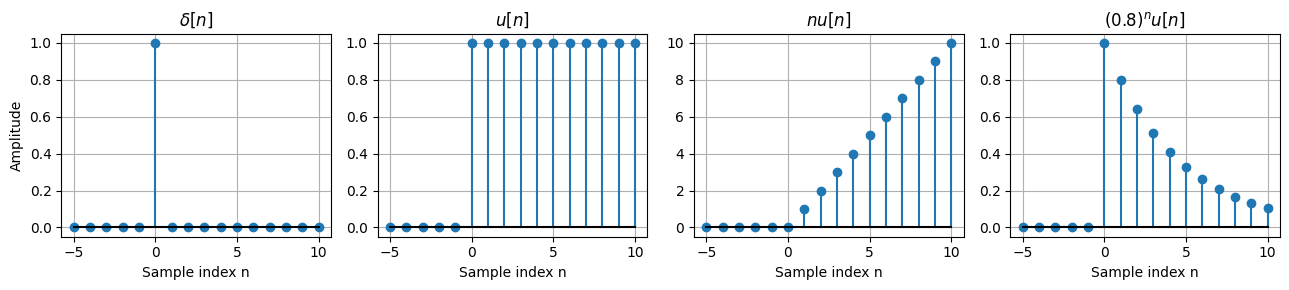

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)       # Unit impulse δ[n]
step = (n >= 0).astype(float)        # Unit step u[n]
ramp = n * step                      # Unit ramp n u[n]
exponential = (0.8**n) * step        # Decaying exponential

sequences = [delta, step, ramp, exponential]
titles = [r"$\delta[n]$", r"$u[n]$", r"$n u[n]$", r"$(0.8)^n u[n]$"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, values, title in zip(axes, sequences, titles):
    ax.stem(n, values, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Sample index n")
axes[0].set_ylabel("Amplitude")
plt.tight_layout(); plt.show()

## Task 1.2 — Change the parameters

First compare $(a)^n u[n]$ for three values of $a$. Then compare two cosine sequences.

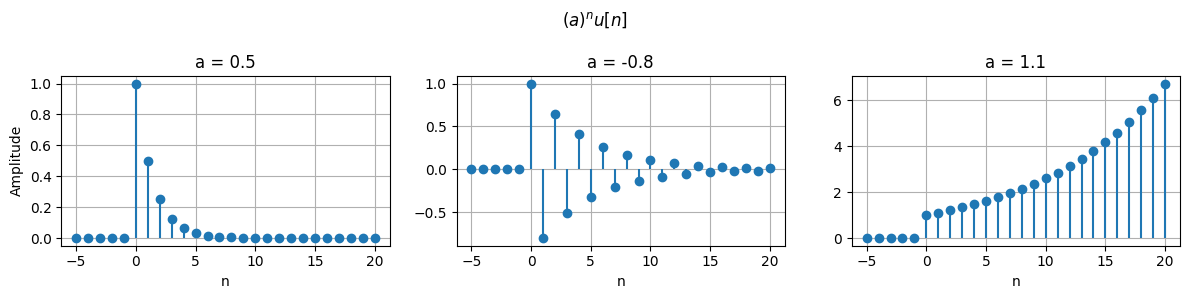

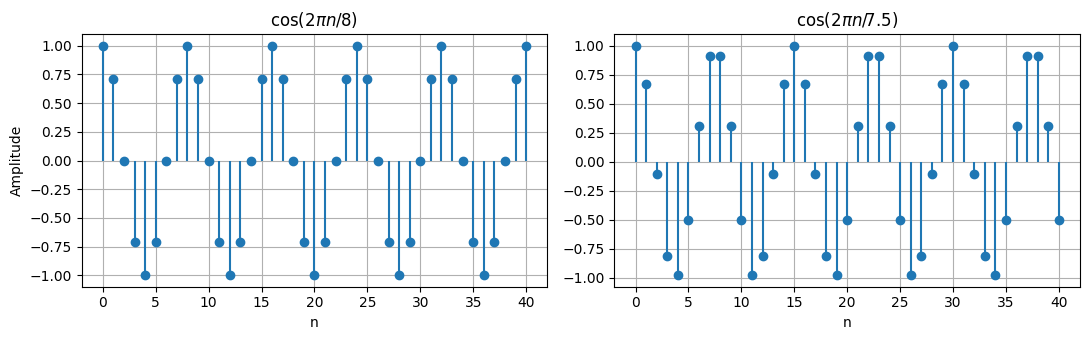

In [3]:
n_exp = np.arange(-5, 21)
values_a = [0.5, -0.8, 1.1]
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, a in zip(axes, values_a):
    y = (a**n_exp) * (n_exp >= 0)
    ax.stem(n_exp, y, basefmt=" ")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
axes[0].set_ylabel("Amplitude")
plt.suptitle(r"$(a)^n u[n]$")
plt.tight_layout(); plt.show()

n_cos = np.arange(0, 41)
cos_8 = np.cos(2*np.pi*n_cos/8)
cos_75 = np.cos(2*np.pi*n_cos/7.5)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, y, title in zip(axes, [cos_8, cos_75],
                         [r"$\cos(2\pi n/8)$", r"$\cos(2\pi n/7.5)$"]):
    ax.stem(n_cos, y, basefmt=" ")
    ax.set_title(title); ax.set_xlabel("n")
axes[0].set_ylabel("Amplitude")
plt.tight_layout(); plt.show()

**Both cosine sequences repeat exactly.** The first has period 8 samples. Since $1/7.5=2/15$ cycles per sample, the second repeats after 15 samples. In discrete time, a sinusoid is periodic when its cycles per sample are a rational number.

## Task 1.3 — Load, plot and play audio

Upload a 3–5 second voice recording as a WAV file when prompted. If you do not have one, cancel the picker and the notebook will generate a short test tone.

Saving ATR.opus to ATR.opus
Generated 440 Hz test tone
Sampling rate: 16000 Hz
Duration: 2.00 s
Mono samples for one minute at this rate: 960,000


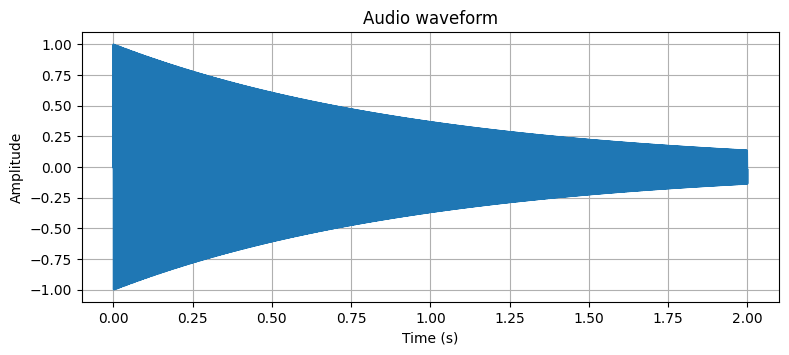

In [4]:
try:
    from google.colab import files
    uploaded = files.upload()
    wav_files = [name for name in uploaded if name.lower().endswith(".wav")]
except ImportError:
    wav_files = [str(path) for path in Path(".").glob("*.wav")]

if wav_files:
    filename = next((name for name in wav_files if Path(name).name.lower() == "my_voice.wav"), wav_files[0])
    fs, raw = wavfile.read(filename)
    raw_dtype = raw.dtype
    samples = raw.astype(np.float64)
    if samples.ndim == 2:
        samples = samples.mean(axis=1)  # Stereo to mono
    if np.issubdtype(raw_dtype, np.integer):
        info = np.iinfo(raw_dtype)
        x = samples / max(abs(info.min), info.max)
    else:
        x = samples
    source = f"Uploaded file: {filename}"
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2*np.pi*440*t) * np.exp(-t)
    source = "Generated 440 Hz test tone"

peak = np.max(np.abs(x)) if len(x) else 0
if peak > 0:
    x = x / peak

t = np.arange(len(x)) / fs
print(source)
print(f"Sampling rate: {fs} Hz")
print(f"Duration: {len(x)/fs:.2f} s")
print(f"Mono samples for one minute at this rate: {fs*60:,}")

plt.plot(t, x)
plt.xlabel("Time (s)"); plt.ylabel("Amplitude")
plt.title("Audio waveform"); plt.show()
display(Audio(x, rate=fs))

**Your recording:** _After listening, briefly describe what you recorded and whether the playback sounds as expected._

## Task 1.4 — Octave (optional)

The same unit-step plot in Octave can be made with:

```octave
n = -5:10;
stem(n, double(n >= 0));
xlabel('n'); title('Unit step');
```

The main syntax difference is that Octave uses `^` for scalar powers and `.^` for element-by-element powers of vectors.

## Task 1.5 — Git repository and submission

Create a repository named `COU07506-labs` on GitHub, GitLab, or locally. Add and commit this notebook. Copy the repository URL into the field below, then save the notebook again. Submit the notebook on DIT-eLMS with the repository link included.

**Git repository URL:** _https://github.com/tambweahmad6-rgb/COU07506-labs.git_

The lab also asks your group to discuss two possible mini-project topics. Examples to consider are speech-noise reduction and simple audio classification.

## Analysis questions

### 1. What is your phone recording's sampling rate? How many mono samples are in one minute?

Use the sampling rate printed above. The count is

\[N=f_s\times60.\]

For example, at 44,100 Hz, one minute contains $44{,}100\times60=2{,}646{,}000$ mono samples. Use your own printed $f_s$ for your answer.

### 2. Why is a stem plot better than a continuous line for $x[n]$?

A discrete-time signal exists only at integer sample indices. Stems show the value at each sample without suggesting that the signal is defined continuously between samples.

### 3. What system property would an impulse response $(1.1)^n u[n]$ violate?

It grows and is not absolutely summable. An LTI system is BIBO stable only if its impulse response is absolutely summable, so this impulse response would indicate an **unstable** system.

## Before submitting

- Enter your name and registration number.
- Run the notebook from top to bottom.
- Add your actual recording observation and use its printed sampling rate in Analysis Question 1.
- Save as `COU07506_Week01_<RegNo>.ipynb`, include the Git repository URL, and submit the notebook on DIT-eLMS.